# Bagian 2: Agregasi Panel Temporal & Rekayasa 10 Fitur Inti Multi-Sinyal

**Cakupan Notebook (Tahap 4):**
- Pembentukan panel seimbang `118 skill × 23 kuartal` (`2.714` observasi skill-kuartal) dan stabilisasi *Empirical Bayes Shrinkage*.
- Ekstraksi **10 fitur inti multi-sinyal kausal** bebas kebocoran masa depan:
  1. **Demand Dynamics (`3` fitur):** `qoq_growth_smoothed`, `delta_share_1q`, `ema_ratio_short_long`
  2. **Context Evolution (`3` fitur):** `cooc_weighted_degree_roll4`, `delta_weighted_degree_1q`, `bridging_ratio_roll4`
  3. **Role Expansion (`2` fitur):** `role_entropy_roll4`, `role_weighted_traction`
  4. **Historical Maturity (`2` fitur):** `maturity_drawdown_ratio`, `maturity_headroom`
- Visualisasi trajektori permintaan skill (**Gambar 2**).


## 1. Setup Lingkungan & Modul Agregasi Panel Kuartalan


In [1]:
import os
import warnings
from pathlib import Path
from dataclasses import dataclass
from typing import List, Dict, Tuple
import pandas as pd

# Nonaktifkan inferensi ArrowStringArray otomatis pada Pandas >= 2.2 / 3.0
# untuk mencegah ArrowException (ChunkedArray.to_numpy wrapping error) pada teks deskripsi panjang
try:
    pd.options.future.infer_string = False
except Exception:
    pass

warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

PROJECT_ROOT = Path(os.environ.get("EMERGING_SKILLS_ROOT", Path.cwd()))
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DEFAULT_RAW_CSV = Path(
    os.environ.get(
        "THEIRSTACK_CSV_PATH",
        str(PROJECT_ROOT / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv"),
    )
)
if not DEFAULT_RAW_CSV.exists():
    DEFAULT_RAW_CSV = PROJECT_ROOT / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv"

@dataclass
class PipelineConfig:
    """Centralized, reproducible configuration for all pipeline stages."""

    # 1. Paths
    project_root: Path = PROJECT_ROOT
    raw_data_path: Path = DEFAULT_RAW_CSV
    processed_dir: Path = PROJECT_ROOT / "data" / "processed"
    outputs_dir: Path = PROJECT_ROOT / "outputs"
    audit_dir: Path = PROJECT_ROOT / "outputs" / "audit"
    features_dir: Path = PROJECT_ROOT / "outputs" / "features"
    predictions_dir: Path = PROJECT_ROOT / "outputs" / "predictions"
    metrics_dir: Path = PROJECT_ROOT / "outputs" / "metrics"
    lead_time_dir: Path = PROJECT_ROOT / "outputs" / "lead_time"
    figures_dir: Path = PROJECT_ROOT / "outputs" / "figures"
    models_dir: Path = PROJECT_ROOT / "models"

    # 2. Preprocessing & Filtering Parameters
    deduplicate_within_quarter: bool = True
    require_it_relevance: bool = True
    use_raw_extracted_skills_fallback_when_desc_empty: bool = True

    # 3. Temporal & Panel Parameters
    min_quarter_postings_for_complete: int = 150
    max_postings_per_company_quarter: int = 5
    min_total_skill_mentions: int = 5
    min_history_quarters: int = 2
    epsilon_share: float = 0.002

    # 4. Co-occurrence Network Parameters (M2: Context Evolution)
    min_cooccurrence_count: int = 2
    jaccard_edge_threshold: float = 0.01

    # 5. Primary Target Future Emergence Definition:
    #    Causal Pre-Evaluation Quantile-Anchored Risk Set + Anti-Mean-Reversion + Binomial SE Guard (H = 2 Quarters)
    horizon_quarters: int = 2
    target_mode: str = "causal_quantile_anchored_optimal_with_multi_regime_se_audit"
    restrict_to_risk_set: bool = True
    use_quantile_anchored_primary_rule: bool = True
    anchor_max_quarter_idx: int = 6  # = first_eval_quarter_idx (9) - H (2) - 1 -> Fold 1 Train Window (2021-Q3..2022-Q3)

    # Parameter Kuantil Kausal Utama (ditetapkan pada jendela jangkar pra-evaluasi q_idx 2..6):
    risk_set_roll4_quantile: float = 0.60      # P60(causal_roll4_share) pada jendela jangkar pra-evaluasi
    risk_set_cummax_quantile: float = 0.65     # P65(causal_cummax_share) pada jendela jangkar pra-evaluasi
    emergence_abs_gain_quantile: float = 0.65  # P65(abs_gain_ref) kandidat pada jendela jangkar pra-evaluasi
    emergence_rel_gain_quantile: float = 0.65  # P65(rel_gain_ref) kandidat pada jendela jangkar pra-evaluasi

    # Parameter Ketahanan Fluktuasi Permintaan & Daya Pisah Tingkat Skill:
    use_anti_mean_reversion_baseline: bool = False  # False pada Rezim Optimal Utama; True pada Rezim Audit Ketat SE (Tahap 5C & 6B)
    min_se_guard_multiplier: float = 0.0            # 0.0 pada Rezim Optimal Utama; diuji bertahap 0.5x, 1.0x, 1.5x, 2.0x SE (Bukti Yazdanian et al., 2022)
    require_sustained_horizon_mean: bool = False    # False pada Rezim Optimal Utama; True pada Rezim Audit Ketat SE (Tahap 5C & 6B)
    se_guard_audit_levels: Tuple[float, ...] = (0.5, 1.0, 1.5, 2.0)

    # Ambang numerik hasil proyeksi kuantil jangkar pra-evaluasi (diperbarui otomatis dari data oleh
    # fit_causal_quantile_thresholds_from_anchor() pada Tahap 5; bukan lagi angka tetap 5,0% / 7,5%):
    max_baseline_share: float = 0.04737
    max_career_cummax_share: float = 0.07938
    min_future_job_count: int = 3
    min_future_abs_share_gain: float = 0.0035
    min_future_rel_share_gain: float = 0.25
    min_future_cooc_degree: float = 0.0
    min_future_role_entropy: float = 0.0

    # 6. Walk-Forward Validation Parameters (Section 10)
    first_eval_quarter_idx: int = 9
    test_window_size: int = 2
    validation_folds_count: int = 4
    top_k_values: Tuple[int, ...] = (5, 10, 15)

    # 7. Early Warning & Lead Time Parameters (Strictly Horizon-Bounded H=2 Quarters)
    confirmation_consecutive_quarters: int = 1
    default_prob_threshold: float = 0.50

    # 8. Reproducibility & ML Hyperparameters (Section 11)
    random_seed: int = 42
    allow_numpy_scipy_fallback: bool = True

    def ensure_dirs(self) -> None:
        for d in [
            self.processed_dir,
            self.outputs_dir,
            self.audit_dir,
            self.features_dir,
            self.predictions_dir,
            self.metrics_dir,
            self.lead_time_dir,
            self.figures_dir,
            self.models_dir,
        ]:
            d.mkdir(parents=True, exist_ok=True)

# Feature Group Definitions for Ablation Study (4 Core Multi-Indicator Features on Identical Candidate Risk Set)
DEMAND_FEATURES: List[str] = [
    "qoq_growth_smoothed",
    "ema_ratio_short_long",
]

CONTEXT_FEATURES: List[str] = [
    "cooc_weighted_degree_roll4",
]

CONTEXT_SYNERGY_FEATURES: List[str] = []

ROLE_FEATURES: List[str] = [
    "role_entropy_roll4",
]

MATURITY_FEATURES: List[str] = []

ABLATION_FEATURE_SETS: Dict[str, List[str]] = {
    "M1_Demand_Only": DEMAND_FEATURES,
    "M2_Context_Only": CONTEXT_FEATURES,
    "M3_Demand_Context": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES,
    "M4_Demand_Context_Role": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES + ROLE_FEATURES,
    "M5_Full_Multi_Signal": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES + ROLE_FEATURES + MATURITY_FEATURES,
}
import matplotlib.pyplot as plt
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

# Otomatis cari lokasi berkas CSV TheirStack jika dijalankan di direktori lokal (mis. folder scraping/ atau project root)
import pickle
import matplotlib.pyplot as plt
cfg = PipelineConfig()
cfg.ensure_dirs()
_s1_path = cfg.outputs_dir / "demo_state" / "stage01_state.pkl"
if "processed_df" not in globals() and _s1_path.exists():
    with open(_s1_path, "rb") as _f:
        _s1 = pickle.load(_f)
    processed_df = _s1["processed_df"]
    job_skill_long_df = _s1["job_skill_long_df"]
    skill_comparison_df = _s1["skill_comparison_df"]
    audit_tables = _s1["audit_tables"]

from typing import Dict, List, Tuple
import pandas as pd
import numpy as np

import re
from typing import Pattern

RAW_TAXONOMY_DEFINITIONS: Dict[str, Tuple[str, str, List[str], str]] = {
    # -------------------------------------------------------------------------
    # 1. PROGRAMMING LANGUAGES
    # -------------------------------------------------------------------------
    "Python": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])python(?:\s*[23](?:\.[0-9]+)?)?(?![a-zA-Z0-9_])",
        ["python", "python3", "python 3"],
        "Matched via exact token boundary.",
    ),
    "Java": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:java(?:\s*(?:8|11|17|21|ee|se))?|j2ee|jvm)(?![a-zA-Z0-9_]|script)",
        ["java", "java 8", "java 11", "java 17", "j2ee", "jvm"],
        "Negative lookahead prevents matching 'JavaScript'.",
    ),
    "JavaScript": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:javascript|ecmascript|es6\+?|es2015\+?|vanilla\s+js|js\s+framework\w*)(?![a-zA-Z0-9_])",
        ["javascript", "ecmascript", "es6", "es2015", "vanilla js"],
        "Separated from TypeScript and Node.js.",
    ),
    "TypeScript": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])typescript(?![a-zA-Z0-9_])",
        ["typescript"],
        "Matched as distinct statically-typed superset of JS.",
    ),
    "C++": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])c\+\+(?:\s*(?:11|14|17|20))?(?![a-zA-Z0-9_+])",
        ["c++", "c++11", "c++14", "c++17", "c++20"],
        "Custom non-word lookaround handles '+' symbols where \\b fails.",
    ),
    "C#": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:c#|c-sharp)(?![a-zA-Z0-9_#])",
        ["c#", "c-sharp"],
        "Custom non-word lookaround handles '#' symbol where \\b fails. Kept distinct from .NET.",
    ),
    "Golang": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:golang|go\s+language|go\s+programming|(?:written|coding|developing|proficiency|experience|fluent)\s+in\s+go\b|\bgo\s*(?:/|,|\band\b|\bor\b)\s*(?:python|rust|java|c\+\+|kotlin|ruby|scala)|(?:python|rust|java|c\+\+)\s*(?:/|,|\band\b|\bor\b)\s*go\b)(?![a-zA-Z0-9_])",
        ["golang", "go language", "go programming"],
        "Disambiguated from English verb 'go' via programming context patterns.",
    ),
    "Rust": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])rust(?![a-zA-Z0-9_])",
        ["rust"],
        "Systems programming language Rust.",
    ),
    "Scala": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])scala(?![a-zA-Z0-9_])",
        ["scala"],
        "Matched via exact token boundary (does not match 'scalable' or 'scalability').",
    ),
    "Kotlin": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])kotlin(?![a-zA-Z0-9_])",
        ["kotlin"],
        "Matched via exact token boundary.",
    ),
    "Swift": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:swift(?:\s*[45])?|swiftui|rxswift)(?!\s+pace|\s+action|\s+resolution|\s+interaction)(?![a-zA-Z0-9_])",
        ["swift", "swift 5", "swiftui", "rxswift"],
        "Excludes English adjective phrases like 'swift interaction' or 'swift resolution'.",
    ),
    "PHP": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])php(?:\s*[78](?:\.[0-9]+)?)?(?![a-zA-Z0-9_])",
        ["php", "php7", "php8"],
        "Matched via exact token boundary.",
    ),
    "Ruby": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])ruby(?!\s+on\s+rails)(?![a-zA-Z0-9_])",
        ["ruby"],
        "Kept distinct from Ruby on Rails framework via negative lookahead.",
    ),
    "R": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:r\s+programming|r\s+language|rstudio|tidyverse|ggplot2|(?:python|sql|sas|stata)\s*(?:,|/|\band\b|\bor\b)\s*r\b|\br\s*(?:,|/|\band\b|\bor\b)\s*(?:python|sql|sas|stata))(?![a-zA-Z0-9_])",
        ["r programming", "r language", "rstudio", "tidyverse", "ggplot2"],
        "Context-guarded to prevent matching 'R&D' or single-letter abbreviations.",
    ),
    "Bash / Shell": (
        "Programming Languages",
        r"(?<![a-zA-Z0-9_])(?:bash|shell\s+script\w*|zsh|powershell)(?![a-zA-Z0-9_])",
        ["bash", "shell scripting", "zsh", "powershell"],
        "Scripting & shell automation languages.",
    ),

    # -------------------------------------------------------------------------
    # 2. WEB, BACKEND & API FRAMEWORKS
    # -------------------------------------------------------------------------
    ".NET": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:\.net(?:\s*core|\s*framework|\s*[45678](?:\.[0-9]+)?)?|asp\.net(?:\s*core|\s*mvc)?|dotnet)(?![a-zA-Z0-9_])",
        [".net", ".net core", ".net framework", "asp.net", "dotnet"],
        "Custom non-word lookbehind handles leading dot in '.NET' and keeps it separate from C#.",
    ),
    "React": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:react(?:\.js|js)?)(?!\s*[-\s]?native)(?![a-zA-Z0-9_])",
        ["react", "react.js", "reactjs"],
        "Kept distinct from React Native via negative lookahead.",
    ),
    "Angular": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:angular(?:\.js|js|\s*[0-9]+)?)(?![a-zA-Z0-9_])",
        ["angular", "angularjs", "angular 2+"],
        "Frontend framework Angular.",
    ),
    "Vue.js": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:vue(?:\.js|js|\s*[23])?|vuex|nuxt(?:\.js|js)?)(?![a-zA-Z0-9_])",
        ["vue", "vue.js", "vuejs", "vuex", "nuxt.js"],
        "Vue ecosystem.",
    ),
    "Next.js": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])next(?:\.js|js)(?![a-zA-Z0-9_])",
        ["next.js", "nextjs"],
        "Requires '.js' or 'js' suffix to never match English word 'next'.",
    ),
    "Node.js": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:node(?:\.js|js)|express(?:\.js|js)|nestjs|nest\.js)(?![a-zA-Z0-9_])",
        ["node.js", "nodejs", "express.js", "nestjs"],
        "Server-side JS runtime and frameworks.",
    ),
    "Django": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])django(?![a-zA-Z0-9_])",
        ["django", "django rest framework"],
        "Python web framework Django.",
    ),
    "FastAPI": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])fastapi(?![a-zA-Z0-9_])",
        ["fastapi"],
        "Modern async Python API framework.",
    ),
    "Flask": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])flask(?![a-zA-Z0-9_])",
        ["flask"],
        "Python micro-framework Flask.",
    ),
    "Spring Boot": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:spring\s*boot|spring\s+framework|spring\s+cloud|spring\s+mvc|spring\s+security)(?![a-zA-Z0-9_])",
        ["spring boot", "springboot", "spring framework", "spring cloud", "spring mvc"],
        "Requires 'boot/framework/cloud/mvc/security' to avoid matching season 'spring'.",
    ),
    "Ruby on Rails": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:ruby\s+on\s+rails|rails\s+framework|\bror\b)(?![a-zA-Z0-9_])",
        ["ruby on rails", "rails framework", "ror"],
        "Kept distinct from standalone Ruby language.",
    ),
    "Laravel": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])laravel(?![a-zA-Z0-9_])",
        ["laravel"],
        "PHP web framework Laravel.",
    ),
    "Tailwind CSS": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:tailwind\s*css|tailwindcss)(?![a-zA-Z0-9_])",
        ["tailwind css", "tailwindcss"],
        "Utility-first CSS framework.",
    ),
    "GraphQL": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:graphql|graph\s+ql|apollo\s+graphql)(?![a-zA-Z0-9_])",
        ["graphql", "graph ql", "apollo graphql"],
        "API query language GraphQL.",
    ),
    "REST API": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:rest(?:ful)?\s+api\w*|restful\s+(?:web\s+)?services|rest\s+web\s+services|openapi|swagger)(?![a-zA-Z0-9_])",
        ["rest api", "restful api", "restful services", "openapi", "swagger"],
        "Requires API/service context to avoid matching English word 'rest'.",
    ),
    "gRPC": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:grpc|protobuf|protocol\s+buffers)(?![a-zA-Z0-9_])",
        ["grpc", "protobuf", "protocol buffers"],
        "High-performance RPC framework.",
    ),
    "Microservices": (
        "Web & Backend",
        r"(?<![a-zA-Z0-9_])(?:microservice\w*|micro-service\w*)(?![a-zA-Z0-9_])",
        ["microservices", "microservice", "micro-services"],
        "Microservices architecture.",
    ),

    # -------------------------------------------------------------------------
    # 3. MOBILE & CROSS-PLATFORM
    # -------------------------------------------------------------------------
    "iOS": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])(?:ios|xcode|cocoapods|objective-c)(?![a-zA-Z0-9_])",
        ["ios", "xcode", "cocoapods", "objective-c"],
        "Apple mobile ecosystem.",
    ),
    "Android": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])(?:android(?:\s+sdk|\s+studio|\s+jetpack|\s+ndk)?)(?![a-zA-Z0-9_])",
        ["android", "android sdk", "android studio", "android jetpack"],
        "Android mobile ecosystem.",
    ),
    "React Native": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])react[\s-]+native(?![a-zA-Z0-9_])",
        ["react native", "react-native"],
        "Kept distinct from web React.",
    ),
    "Flutter": (
        "Mobile & Cross-Platform",
        r"(?<![a-zA-Z0-9_])flutter(?![a-zA-Z0-9_])",
        ["flutter"],
        "Cross-platform UI toolkit Flutter.",
    ),

    # -------------------------------------------------------------------------
    # 4. DATABASES & DATA WAREHOUSES (Strictly Separated!)
    # -------------------------------------------------------------------------
    "SQL": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:sql|t-sql|pl/sql|ansi\s+sql)(?![a-zA-Z0-9_])",
        ["sql", "t-sql", "pl/sql"],
        "Matches standalone SQL/T-SQL/PL-SQL; does NOT auto-trigger on PostgreSQL/MySQL/SQLite/NoSQL.",
    ),
    "PostgreSQL": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:postgresql|postgres|postgis)(?![a-zA-Z0-9_])",
        ["postgresql", "postgres", "postgis"],
        "Kept strictly separate from generic SQL, MySQL, and SQLite.",
    ),
    "MySQL": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:mysql|mariadb)(?![a-zA-Z0-9_])",
        ["mysql", "mariadb"],
        "Kept strictly separate from generic SQL, PostgreSQL, and SQLite.",
    ),
    "SQLite": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])sqlite(?:3)?(?![a-zA-Z0-9_])",
        ["sqlite", "sqlite3"],
        "Kept strictly separate from generic SQL, PostgreSQL, and MySQL.",
    ),
    "SQL Server": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:sql\s+server|mssql|ms-sql|ssrs|ssis|ssas)(?![a-zA-Z0-9_])",
        ["sql server", "mssql", "ms-sql", "ssis", "ssrs", "ssas"],
        "Microsoft SQL Server ecosystem.",
    ),
    "Oracle DB": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:oracle\s+database|oracle\s+db|oracle\s+rdbms|oracle\s+(?:11g|12c|19c))(?![a-zA-Z0-9_])",
        ["oracle database", "oracle db", "oracle 12c", "oracle 19c"],
        "Contextualized to Oracle Database rather than company name alone.",
    ),
    "MongoDB": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])mongodb(?![a-zA-Z0-9_])",
        ["mongodb"],
        "Document NoSQL database MongoDB.",
    ),
    "Redis": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])redis(?![a-zA-Z0-9_])",
        ["redis"],
        "In-memory data store Redis.",
    ),
    "Elasticsearch": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:elasticsearch|elastic\s+search|opensearch|elk\s+stack)(?![a-zA-Z0-9_])",
        ["elasticsearch", "elastic search", "opensearch", "elk stack"],
        "Search & analytics engine.",
    ),
    "Cassandra": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:apache\s+cassandra|cassandra)(?![a-zA-Z0-9_])",
        ["cassandra", "apache cassandra"],
        "Wide-column store Cassandra.",
    ),
    "DynamoDB": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])dynamodb(?![a-zA-Z0-9_])",
        ["dynamodb", "aws dynamodb"],
        "Managed NoSQL database DynamoDB.",
    ),
    "Snowflake": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])snowflake(?!\s+schema)(?![a-zA-Z0-9_])",
        ["snowflake"],
        "Cloud data warehouse Snowflake (excludes 'snowflake schema' modeling term).",
    ),
    "BigQuery": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:bigquery|big\s+query)(?![a-zA-Z0-9_])",
        ["bigquery", "big query"],
        "GCP serverless data warehouse BigQuery.",
    ),
    "Redshift": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])redshift(?![a-zA-Z0-9_])",
        ["redshift", "aws redshift"],
        "AWS cloud data warehouse Redshift.",
    ),
    "Databricks": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:databricks|delta\s+lake)(?![a-zA-Z0-9_])",
        ["databricks", "delta lake"],
        "Lakehouse platform Databricks.",
    ),
    "Vector Database": (
        "Databases & Warehouses",
        r"(?<![a-zA-Z0-9_])(?:vector\s+database\w*|vector\s+db\w*|vector\s+store\w*|vector\s+search|pinecone|weaviate|milvus|qdrant|chromadb|pgvector|faiss)(?![a-zA-Z0-9_])",
        ["vector database", "vector db", "vector store", "pinecone", "weaviate", "milvus", "qdrant", "chromadb", "pgvector", "faiss"],
        "Vector databases & similarity search engines for embeddings/RAG.",
    ),

    # -------------------------------------------------------------------------
    # 5. DATA ENGINEERING, BIG DATA & BI (Power BI vs Tableau vs Looker Separated!)
    # -------------------------------------------------------------------------
    "Data Engineering": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:data\s+engineering|data\s+pipeline\w*|etl\s+pipeline\w*|\betl\b|\belt\b)(?![a-zA-Z0-9_])",
        ["data engineering", "data pipelines", "etl", "elt"],
        "Data pipeline & ETL/ELT engineering.",
    ),
    "Data Governance": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:data\s+governance|data\s+catalog\w*|data\s+lineage|collibra|alation)(?![a-zA-Z0-9_])",
        ["data governance", "data catalog", "data lineage", "collibra", "alation"],
        "Enterprise data governance and lineage.",
    ),
    "Spark": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+spark|\bspark\b(?:\s+sql|\s+streaming|\s+mllib)?)(?!\s+your\s+interest)(?![a-zA-Z0-9_])",
        ["spark", "apache spark", "spark sql", "spark streaming"],
        "Kept distinct from PySpark.",
    ),
    "PySpark": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])pyspark(?![a-zA-Z0-9_])",
        ["pyspark"],
        "Python API for Apache Spark.",
    ),
    "Hadoop": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:hadoop|hdfs|mapreduce)(?![a-zA-Z0-9_])",
        ["hadoop", "hdfs", "mapreduce"],
        "Apache Hadoop ecosystem.",
    ),
    "Hive": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+hive|\bhive\b)(?![a-zA-Z0-9_])",
        ["hive", "apache hive"],
        "Apache Hive data warehouse.",
    ),
    "Kafka": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+kafka|\bkafka\b)(?![a-zA-Z0-9_])",
        ["kafka", "apache kafka"],
        "Distributed event streaming platform Kafka.",
    ),
    "Flink": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+flink|\bflink\b)(?![a-zA-Z0-9_])",
        ["flink", "apache flink"],
        "Stateful stream processing framework Apache Flink.",
    ),
    "Airflow": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:apache\s+airflow|\bairflow\b)(?![a-zA-Z0-9_])",
        ["airflow", "apache airflow"],
        "Workflow orchestration platform Airflow.",
    ),
    "dbt": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:dbt|data\s+build\s+tool)(?![a-zA-Z0-9_])",
        ["dbt", "data build tool"],
        "Analytics engineering transformation tool dbt.",
    ),
    "Power BI": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:power\s*bi|dax\s+queries)(?![a-zA-Z0-9_])",
        ["power bi", "powerbi"],
        "Strictly separated from Tableau and Looker!",
    ),
    "Tableau": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])tableau(?![a-zA-Z0-9_])",
        ["tableau"],
        "Strictly separated from Power BI and Looker!",
    ),
    "Looker": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:looker|lookml)(?![a-zA-Z0-9_])",
        ["looker", "lookml"],
        "Strictly separated from Power BI and Tableau!",
    ),
    "Pandas": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])(?:pandas|geopandas)(?![a-zA-Z0-9_])",
        ["pandas", "geopandas"],
        "Python tabular analysis library Pandas.",
    ),
    "NumPy": (
        "Data & Analytics",
        r"(?<![a-zA-Z0-9_])numpy(?![a-zA-Z0-9_])",
        ["numpy"],
        "Python numerical array library NumPy.",
    ),

    # -------------------------------------------------------------------------
    # 6. CLOUD, DEVOPS, OBSERVABILITY & VERSION CONTROL (Git/GitHub/GitLab Separated!)
    # -------------------------------------------------------------------------
    "AWS": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:aws|amazon\s+web\s+services)(?![a-zA-Z0-9_])",
        ["aws", "amazon web services"],
        "Amazon Web Services cloud.",
    ),
    "Azure": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:azure|microsoft\s+azure)(?![a-zA-Z0-9_])",
        ["azure", "microsoft azure"],
        "Microsoft Azure cloud.",
    ),
    "GCP": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:gcp|google\s+cloud(?:\s+platform)?)(?![a-zA-Z0-9_])",
        ["gcp", "google cloud", "google cloud platform"],
        "Google Cloud Platform.",
    ),
    "Serverless": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:serverless|aws\s+lambda|cloud\s+functions|azure\s+functions)(?![a-zA-Z0-9_])",
        ["serverless", "aws lambda", "cloud functions", "azure functions"],
        "Serverless compute paradigm.",
    ),
    "Docker": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:docker|dockerfile|docker-compose)(?![a-zA-Z0-9_])",
        ["docker", "dockerfile", "docker-compose"],
        "Container runtime Docker.",
    ),
    "Kubernetes": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:kubernetes|k8s|eks|gke|aks|helm\s+chart\w*)(?![a-zA-Z0-9_])",
        ["kubernetes", "k8s", "eks", "gke", "aks", "helm charts"],
        "Container orchestration Kubernetes.",
    ),
    "Containerization": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:containerization|containerisation|containerized|container\s+orchestration)(?![a-zA-Z0-9_])",
        ["containerization", "containerized", "container orchestration"],
        "Containerization concepts.",
    ),
    "Terraform": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:terraform|terragrunt)(?![a-zA-Z0-9_])",
        ["terraform", "terragrunt"],
        "HashiCorp Terraform IaC tool.",
    ),
    "IaC": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:infrastructure\s+as\s+a?\s*code|infrastructure-as-code|\biac\b|\biaac\b|cloudformation|pulumi)(?![a-zA-Z0-9_])",
        ["infrastructure as code", "iac", "cloudformation", "pulumi"],
        "Infrastructure as Code paradigm & tools.",
    ),
    "Ansible": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])ansible(?![a-zA-Z0-9_])",
        ["ansible"],
        "Configuration management Ansible.",
    ),
    "CI/CD": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:ci/cd|ci\s*/\s*cd|cicd|continuous\s+integration|continuous\s+delivery|continuous\s+deployment|jenkins|circleci|teamcity|bamboo)(?![a-zA-Z0-9_])",
        ["ci/cd", "cicd", "continuous integration", "continuous delivery", "jenkins", "circleci"],
        "CI/CD automation pipelines.",
    ),
    "GitOps": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:gitops|argocd|argo\s+cd|fluxcd)(?![a-zA-Z0-9_])",
        ["gitops", "argocd", "argo cd", "fluxcd"],
        "Declarative GitOps continuous delivery.",
    ),
    "Prometheus": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:prometheus|promql)(?![a-zA-Z0-9_])",
        ["prometheus", "promql"],
        "Time-series monitoring Prometheus.",
    ),
    "Grafana": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])grafana(?![a-zA-Z0-9_])",
        ["grafana"],
        "Observability dashboarding Grafana.",
    ),
    "Datadog": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])datadog(?![a-zA-Z0-9_])",
        ["datadog"],
        "Cloud monitoring platform Datadog.",
    ),
    "Observability": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:observability|opentelemetry|open\s+telemetry)(?![a-zA-Z0-9_])",
        ["observability", "opentelemetry", "open telemetry"],
        "System observability & telemetry.",
    ),
    "Linux": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:linux|ubuntu|redhat|rhel|centos|debian|unix)(?![a-zA-Z0-9_])",
        ["linux", "ubuntu", "redhat", "rhel", "centos", "debian", "unix"],
        "Linux/Unix operating systems.",
    ),
    "Git": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:git|gitflow)(?![a-zA-Z0-9_])",
        ["git", "gitflow"],
        "Strictly separated from GitHub and GitLab via exact token boundary!",
    ),
    "GitHub": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:github|github\s+actions)(?![a-zA-Z0-9_])",
        ["github", "github actions"],
        "Strictly separated from standalone Git and GitLab!",
    ),
    "GitLab": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])(?:gitlab|gitlab\s+ci)(?![a-zA-Z0-9_])",
        ["gitlab", "gitlab ci"],
        "Strictly separated from standalone Git and GitHub!",
    ),
    "Selenium": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])selenium(?![a-zA-Z0-9_])",
        ["selenium", "selenium webdriver"],
        "Browser test automation Selenium.",
    ),
    "Cypress": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])cypress(?![a-zA-Z0-9_])",
        ["cypress"],
        "Modern web E2E testing framework Cypress.",
    ),
    "Playwright": (
        "Cloud & DevOps",
        r"(?<![a-zA-Z0-9_])playwright(?![a-zA-Z0-9_])",
        ["playwright"],
        "Modern browser testing & automation framework Playwright.",
    ),

    # -------------------------------------------------------------------------
    # 7. AI, MACHINE LEARNING, DEEP LEARNING & GENERATIVE AI
    # -------------------------------------------------------------------------
    "Data Science": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])data\s+scien(?:ce|tist\w*)(?![a-zA-Z0-9_])",
        ["data science", "data scientist"],
        "Data science discipline.",
    ),
    "Machine Learning": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])machine\s+learning(?![a-zA-Z0-9_])",
        ["machine learning"],
        "Machine learning discipline.",
    ),
    "Deep Learning": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:deep\s+learning|neural\s+network\w*|cnn\w*|rnn\w*|lstm\w*)(?![a-zA-Z0-9_])",
        ["deep learning", "neural networks", "cnn", "rnn", "lstm"],
        "Deep neural network architectures.",
    ),
    "TensorFlow": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])tensorflow(?![a-zA-Z0-9_])",
        ["tensorflow"],
        "Kept strictly separate from Keras and PyTorch.",
    ),
    "Keras": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])keras(?![a-zA-Z0-9_])",
        ["keras"],
        "Kept strictly separate from TensorFlow.",
    ),
    "PyTorch": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])pytorch(?![a-zA-Z0-9_])",
        ["pytorch"],
        "Deep learning framework PyTorch.",
    ),
    "Scikit-Learn": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:scikit-learn|scikit\s+learn|sklearn)(?![a-zA-Z0-9_])",
        ["scikit-learn", "scikit learn", "sklearn"],
        "Classical ML library Scikit-Learn.",
    ),
    "NLP": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:natural\s+language\s+processing|\bnlp\b|spacy|nltk)(?![a-zA-Z0-9_])",
        ["nlp", "natural language processing", "spacy", "nltk"],
        "Natural Language Processing.",
    ),
    "Computer Vision": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:computer\s+vision|opencv|object\s+detection|image\s+segmentation)(?![a-zA-Z0-9_])",
        ["computer vision", "opencv", "object detection"],
        "Computer Vision & OpenCV.",
    ),
    "MLOps": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:mlops|ml\s+ops|mlflow|kubeflow|sagemaker|vertex\s+ai)(?![a-zA-Z0-9_])",
        ["mlops", "ml ops", "mlflow", "kubeflow", "sagemaker", "vertex ai"],
        "Machine Learning Operations & model lifecycle platforms.",
    ),
    "LLM": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:large\s+language\s+model\w*|\bllms?\b|gpt-?[34]\w*|chatgpt|openai\s+api|claude|llama\s*[23]?|mistral)(?![a-zA-Z0-9_])",
        ["llm", "llms", "large language models", "gpt-4", "openai api", "llama", "claude", "mistral"],
        "Large Language Models.",
    ),
    "Generative AI": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:generative\s+ai|genai|gen\s+ai|foundation\s+model\w*|diffusion\s+model\w*|stable\s+diffusion)(?![a-zA-Z0-9_])",
        ["generative ai", "genai", "gen ai", "foundation models", "diffusion models"],
        "Generative AI systems & foundation models.",
    ),
    "RAG": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:retrieval[\s-]+augmented[\s-]+generation|\brag\b)(?![a-zA-Z0-9_])",
        ["retrieval-augmented generation", "retrieval augmented generation", "rag pipeline", "rag"],
        "Context-guarded so 'RAG' (Red-Amber-Green status reporting) is never misclassified as AI RAG!",
    ),
    "AI Agents": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:ai\s+agents?|agentic\s+(?:ai|workflow\w*|system\w*)|multi-agent\s+system\w*|autogen|crewai|langgraph)(?![a-zA-Z0-9_])",
        ["ai agents", "agentic ai", "agentic workflows", "multi-agent", "autogen", "crewai", "langgraph"],
        "Autonomous AI Agents & multi-agent frameworks.",
    ),
    "LangChain": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:langchain|langsmith)(?![a-zA-Z0-9_])",
        ["langchain", "langsmith"],
        "LLM orchestration framework LangChain.",
    ),
    "LlamaIndex": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:llamaindex|llama[\s_-]*index)(?![a-zA-Z0-9_])",
        ["llamaindex", "llama-index"],
        "Data framework for LLM applications LlamaIndex.",
    ),
    "Prompt Engineering": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:prompt\s+engineering|prompt\s+design|prompt\s+tuning|few-shot\s+prompting|chain-of-thought)(?![a-zA-Z0-9_])",
        ["prompt engineering", "prompt design", "prompt tuning", "chain-of-thought"],
        "Prompt engineering & optimization.",
    ),
    "Fine-Tuning": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:fine[\s-]+tun(?:ing|ed)|peft|\blora\b|qlora|rlhf|instruction\s+tuning)(?![a-zA-Z0-9_])",
        ["fine-tuning", "fine tuning", "peft", "lora", "qlora", "rlhf"],
        "Model fine-tuning & parameter-efficient adaptation.",
    ),
    "Transformers": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:transformer\s+model\w*|transformer\s+architecture|\btransformers\b|\bbert\b|attention\s+mechanism)(?![a-zA-Z0-9_])",
        ["transformers", "transformer models", "bert", "attention mechanism"],
        "Transformer neural architectures.",
    ),
    "Hugging Face": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:hugging\s*face)(?![a-zA-Z0-9_])",
        ["huggingface", "hugging face"],
        "Hugging Face ecosystem.",
    ),
    "vLLM": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])vllm(?![a-zA-Z0-9_])",
        ["vllm"],
        "High-throughput LLM serving engine vLLM.",
    ),
    "CUDA": (
        "AI / ML & GenAI",
        r"(?<![a-zA-Z0-9_])(?:cuda|tensorrt|triton\s+inference|gpgpu)(?![a-zA-Z0-9_])",
        ["cuda", "tensorrt", "gpgpu"],
        "GPU parallel computing & inference acceleration.",
    ),

    # -------------------------------------------------------------------------
    # 8. SECURITY (Strictly Contextualized — Rejects Generic 'Security')
    # -------------------------------------------------------------------------
    "Cybersecurity": (
        "Security",
        r"(?<![a-zA-Z0-9_])(?:cyber\s*security|cybersecurity|information\s+security|infosec|application\s+security|appsec|devsecops|secops|network\s+security|cloud\s+security|penetration\s+test\w*|pentest\w*|vulnerability\s+(?:assessment|management|scanning)|siem|soc\s+analyst|owasp|cissp|iso\s*27001|nist\s+(?:csf|800)|zero\s+trust|incident\s+response|threat\s+(?:hunting|intelligence|modeling)|cryptography|encryption|iam\s+security)(?![a-zA-Z0-9_])",
        [
            "cybersecurity", "cyber security", "information security", "infosec",
            "application security", "appsec", "devsecops", "network security",
            "cloud security", "penetration testing", "siem", "owasp", "cissp",
            "iso 27001", "zero trust", "threat modeling", "incident response",
        ],
        "Requires explicit technical security context; never matches standalone 'security' (job/social/financial security).",
    ),
    # -------------------------------------------------------------------------
    # 9. OFFICE & PRODUCTIVITY TOOLS (Verb & Context Disambiguated)
    # -------------------------------------------------------------------------
    "Excel": (
        "Office & Productivity",
        r"(?<![a-zA-Z0-9_])(?:ms\.?\s*excel|microsoft\s+excel|excel\s*(?:,|/|&|\band\b|\bdan\b|\bor\b|\batau\b|\bund\b|\()\s*(?:word|power\s*point|powerpoint|outlook|access|google\s*sheets?|g-?sheets?|sheets?|vba|sql|tableau|power\s*bi|looker|python|csv|pdf|macros?|pivot)|(?:word|power\s*point|powerpoint|outlook|google\s*sheets?|g-?sheets?|sheets?|ms\.?\s*office|microsoft\s+office|vba|sql|tableau|power\s*bi|looker|csv|r)\s*(?:,|/|&|\band\b|\bdan\b|\bor\b|\batau\b|\bund\b|\(|:)\s*(?:ms\.?\s*)?excel|excel\s+(?:vba|macros?|pivot(?:\s*tables?)?|formulas?|rumus|functions?|spreadsheets?|sheets?|workbooks?|files?|reports?|reporting|dashboards?|charts?|models?|modeling|modelling|analysis|analytics|skills?|tools?|proficiency|knowledge|experience|expert\w*|advanced|intermediate|basics?|fundamental\w*|yang\s+kuat|atau|dan|dll|dst)|(?:using|use\s+of|utilize|proficient\s+(?:in|with)|proficiency\s+(?:in|with)|experienced?\s+(?:in|with)|knowledge\s+of|mastery\s+of|expert\s+(?:in|with)|skilled\s+(?:in|with)|comfortable\s+with|excellent|advanced|intermediate|basic|strong|familiar\s+with|working\s+knowledge\s+of|menguasai|mahir|mampu\s+mengoperasikan|mengoperasikan|menggunakan|penggunaan|paham|memahami|pengalaman(?:\s+dengan)?|rumusan?|kemampuan|keahlian|keterampilan|ke|in|with)\s+(?:ms\.?\s*|microsoft\s+)?excel|(?:ms\.?\s*office|microsoft\s+office|m\.?s\.?\s*office)[^.\n;]{0,40}\bexcel\b|(?<!\bto\s)(?<!\bwill\s)(?<!\bcan\s)(?<!\byou\s)(?<!\bwe\s)(?<!\bthey\s)(?<!\bmust\s)(?<!\bshould\s)(?<!\bcould\s)(?<!\bwould\s)(?<!\bhelp\s)(?-i:Excel)(?!\s+(?:in|at|within|beyond|under|when|while|during|where|together|and\s+innovate)\b))(?![a-zA-Z0-9_])",
        ["excel", "ms excel", "microsoft excel", "excel vba"],
        "Context-guarded and lookaround-protected against English verb 'to excel' and substrings like 'excellent'/'ExcelHER'.",
    ),
    "Google Sheets": (
        "Office & Productivity",
        r"(?<![a-zA-Z0-9_])(?:google\s+sheets?|google\s+spreadsheets?|g-?sheets?)(?![a-zA-Z0-9_])",
        ["google sheets", "google sheet", "google spreadsheet", "gsheet"],
        "Requires explicit Google Sheets / G-Sheets phrasing to never match CSS stylesheets.",
    ),
    "Microsoft Office": (
        "Office & Productivity",
        r"(?<![a-zA-Z0-9_])(?:microsoft\s+office|ms\.?\s*office|microsoft\s+365|office\s*365|m365)(?![a-zA-Z0-9_])",
        ["microsoft office", "ms office", "office 365", "microsoft 365", "m365"],
        "Requires explicit Microsoft/MS/365 context; rejects generic phrases like back office or head office.",
    ),
    "PowerPoint": (
        "Office & Productivity",
        r"(?<![a-zA-Z0-9_])(?:microsoft\s+power\s*point|ms\.?\s*power\s*point|power\s*point|powerpoint|\.pptx?)(?![a-zA-Z0-9_])",
        ["powerpoint", "ms powerpoint", "microsoft powerpoint", ".pptx"],
        "Matched via PowerPoint or .ppt/.pptx context; avoids ambiguous standalone abbreviations.",
    ),
    "Microsoft Word": (
        "Office & Productivity",
        r"(?<![a-zA-Z0-9_])(?:microsoft\s+word|ms\.?\s*word|(?:excel|power\s*point|powerpoint|outlook)\s*(?:,|/|&|\band\b|\bdan\b)\s*word|word\s*(?:,|/|&|\band\b)\s*(?:excel|power\s*point|powerpoint|outlook))(?!\s*(?:search|puzzle|of\s+mouth|count|cloud))(?![a-zA-Z0-9_])",
        ["microsoft word", "ms word", "word"],
        "Requires explicit Microsoft/MS Word or Office suite pairing (Word & Excel); never matches standalone English 'word'.",
    ),
}

# Pre-compile regex patterns for fast, deterministic execution
COMPILED_TAXONOMY: Dict[str, Tuple[str, Pattern, List[str], str]] = {
    skill: (cat, re.compile(pat, flags=re.IGNORECASE), aliases, note)
    for skill, (cat, pat, aliases, note) in RAW_TAXONOMY_DEFINITIONS.items()
}

def get_taxonomy_dataframe():
    """Return a clean DataFrame documenting all canonical skills, categories, aliases, regexes, and audit notes."""
    import pandas as pd
    rows = []
    for skill, (cat, pat, aliases, note) in RAW_TAXONOMY_DEFINITIONS.items():
        rows.append({
            "canonical_skill": skill,
            "domain_category": cat,
            "aliases_supported": ", ".join(aliases),
            "regex_pattern": pat,
            "audit_rule_note": note,
        })
    return pd.DataFrame(rows)

from typing import Dict, List, Set, Tuple
import pandas as pd
import numpy as np

try:
    pd.options.future.infer_string = False
except Exception:
    pass

# Raw tags in `extracted_skills` that cannot be trusted without text verification
UNTRUSTED_RAW_TAGS_WITHOUT_TEXT = {"Cybersecurity"}

def _to_clean_str_list(series: pd.Series, fill_value: str = "") -> List[str]:
    """
    Safely convert any Pandas Series (including PyArrow ArrowStringArray in Pandas 2.2+/3.0+)
    into a plain Python list[str] via .tolist() without invoking ArrowExtensionArray.to_numpy(),
    preventing PyArrow C++ 'ArrowException: Unknown error: Wrapping ... failed' on long texts.
    """
    if series is None or len(series) == 0:
        return []
    raw_vals = series.tolist()
    cleaned: List[str] = []
    for val in raw_vals:
        if val is None or val is pd.NA or (isinstance(val, float) and np.isnan(val)):
            cleaned.append(fill_value)
        elif isinstance(val, str):
            cleaned.append(val.encode("utf-8", errors="replace").decode("utf-8", errors="replace"))
        else:
            cleaned.append(str(val).encode("utf-8", errors="replace").decode("utf-8", errors="replace"))
    return cleaned

def _to_clean_object_series(series: pd.Series, fill_value: str = "") -> pd.Series:
    """Return a standard Python object-dtype string Series immune to PyArrow string wrapping errors."""
    return pd.Series(_to_clean_str_list(series, fill_value=fill_value), index=series.index, dtype=object)

def extract_skills_from_text(text: str) -> List[Tuple[str, str, str]]:
    """
    Extract canonical skills and their matched surface strings from a single text string.

    Parameters
    ----------
    text : str
        Combined job title and description text.

    Returns
    -------
    List[Tuple[str, str, str]]
        List of (canonical_skill, domain_category, matched_surface_term) tuples.
    """
    if not isinstance(text, str) or not text.strip():
        return []

    found: List[Tuple[str, str, str]] = []
    for skill, (cat, compiled_pat, _, _) in COMPILED_TAXONOMY.items():
        m = compiled_pat.search(text)
        if m:
            found.append((skill, cat, m.group(0).strip()))
    return found

def normalize_skill_alias(raw_name: str) -> str:
    """
    Normalize a raw skill or alias string into its canonical skill entity name.
    Returns empty string if not recognized in the taxonomy.
    """
    if not isinstance(raw_name, str) or not raw_name.strip():
        return ""
    cleaned = raw_name.strip()
    # Direct canonical match (case-insensitive)
    for canonical in RAW_TAXONOMY_DEFINITIONS:
        if cleaned.lower() == canonical.lower():
            return canonical
    # Alias list match
    for canonical, (_, _, aliases, _) in RAW_TAXONOMY_DEFINITIONS.items():
        if cleaned.lower() in [a.lower() for a in aliases]:
            return canonical
    # Regex fallback on isolated token
    for canonical, (_, compiled_pat, _, _) in COMPILED_TAXONOMY.items():
        if compiled_pat.fullmatch(cleaned):
            return canonical
    return ""

def run_batch_skill_extraction(
    df: pd.DataFrame,
    use_raw_fallback_if_desc_empty: bool = True,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Run vectorized regex extraction across all job postings in `df` and generate:
    1. `df_with_skills`: Job postings DataFrame with `canonical_skills` (list), `canonical_skills_str`, `n_skills`, and `extraction_method`.
    2. `job_skill_long_df`: Long-format provenance table `(job_id, year_quarter, canonical_role, canonical_skill, domain_category, extraction_source)`.
    3. `comparison_audit_df`: Audit table comparing raw `extracted_skills` vs audited regex extraction per skill.
    """
    out_df = df.copy()
    n_rows = len(out_df)
    title_list = _to_clean_str_list(out_df["title"], "")
    desc_list = _to_clean_str_list(out_df["description"], "")
    raw_ext = _to_clean_str_list(out_df["extracted_skills"], "")
    combined_texts = [f"{t} \n {d}" for t, d in zip(title_list, desc_list)]
    has_desc_arr = np.array([len(d.strip()) > 10 for d in desc_list], dtype=bool)

    # Boolean matrix: rows = jobs, cols = canonical skills (evaluated directly on Python str list)
    skill_names = list(COMPILED_TAXONOMY.keys())
    skill_cats = {k: v[0] for k, v in COMPILED_TAXONOMY.items()}
    match_matrix = {}

    for skill, (cat, compiled_pat, _, _) in COMPILED_TAXONOMY.items():
        search_fn = compiled_pat.search
        match_matrix[skill] = np.fromiter(
            (search_fn(txt) is not None for txt in combined_texts),
            dtype=bool,
            count=n_rows,
        )

    match_df = pd.DataFrame(match_matrix, index=out_df.index)

    # Build per-job skill lists and long provenance records
    canonical_skills_col: List[List[str]] = []
    extraction_method_col: List[str] = []
    long_records: List[Dict[str, object]] = []

    job_ids = _to_clean_str_list(out_df["job_id"], "")
    yqs = _to_clean_str_list(out_df["year_quarter"], "")
    roles = (
        _to_clean_str_list(out_df["canonical_role"], "")
        if "canonical_role" in out_df.columns
        else _to_clean_str_list(out_df["role_category"], "")
    )

    mat_values = match_df.to_numpy()
    for i in range(len(out_df)):
        row_matches = [skill_names[j] for j in np.flatnonzero(mat_values[i])]
        method = "regex_title_and_description" if has_desc_arr[i] else "regex_title_only"

        # If description is empty and no title skills matched, optionally check safe raw tags
        if not has_desc_arr[i] and use_raw_fallback_if_desc_empty and raw_ext[i].strip():
            for raw_tok in raw_ext[i].split(","):
                norm_s = normalize_skill_alias(raw_tok)
                if norm_s and norm_s not in UNTRUSTED_RAW_TAGS_WITHOUT_TEXT and norm_s not in row_matches:
                    row_matches.append(norm_s)
                    method = "regex_title_plus_safe_raw_tag"

        canonical_skills_col.append(row_matches)
        extraction_method_col.append(method)

        jid = job_ids[i]
        yq = yqs[i]
        rl = roles[i]
        for sk in row_matches:
            long_records.append({
                "job_id": jid,
                "year_quarter": yq,
                "canonical_role": rl,
                "canonical_skill": sk,
                "domain_category": skill_cats[sk],
                "extraction_source": method,
            })

    out_df["canonical_skills_list"] = canonical_skills_col
    out_df["canonical_skills"] = [", ".join(lst) for lst in canonical_skills_col]
    out_df["n_canonical_skills"] = [len(lst) for lst in canonical_skills_col]
    out_df["skill_extraction_method"] = extraction_method_col

    job_skill_long_df = pd.DataFrame(long_records)

    # Build comparison audit table between raw `extracted_skills` and audited `canonical_skills`
    raw_tokens = [
        tok.strip()
        for raw_s in _to_clean_str_list(df["extracted_skills"], "")
        if raw_s.strip()
        for tok in raw_s.split(",")
        if tok.strip()
    ]
    raw_counts = pd.Series(raw_tokens, dtype=object).value_counts() if raw_tokens else pd.Series(dtype=int)
    new_counts = job_skill_long_df["canonical_skill"].value_counts() if len(job_skill_long_df) > 0 else pd.Series(dtype=int)

    all_compared_skills = sorted(set(raw_counts.index).union(set(skill_names)))
    comp_rows = []
    for sk in all_compared_skills:
        r_cnt = int(raw_counts.get(sk, 0))
        n_cnt = int(new_counts.get(sk, 0))
        diff = n_cnt - r_cnt
        status = "Consistent"
        if r_cnt == 0 and n_cnt > 0:
            status = "Newly Separated / Recovered Entity"
        elif sk == "Cybersecurity" and diff < -500:
            status = "Cleaned Generic 'security' False Positives"
        elif sk in ("SQL", "Git", "Power BI") and diff < -100:
            status = "Decoupled Conflated Entities (Postgres/MySQL, GitHub/GitLab, Tableau)"
        elif sk in ("C++", "C#", ".NET") and diff > 200:
            status = "Fixed Special-Character Boundary Regex"
        elif abs(diff) > 50:
            status = "Refined Boundary / Alias Matching"

        comp_rows.append({
            "skill": sk,
            "domain_category": skill_cats.get(sk, "Legacy Raw Tag"),
            "raw_extracted_count": r_cnt,
            "audited_canonical_count": n_cnt,
            "count_difference": diff,
            "audit_diagnosis": status,
        })

    comparison_audit_df = pd.DataFrame(comp_rows).sort_values("audited_canonical_count", ascending=False).reset_index(drop=True)
    return out_df, job_skill_long_df, comparison_audit_df

tax_df = get_taxonomy_dataframe()
tax_df.to_csv(cfg.processed_dir / 'skill_taxonomy_and_aliases.csv', index=False)
print(f'Total skill kanonis dalam taksonomi: {len(tax_df)} skill lintas {tax_df["domain_category"].nunique()} domain TI.')
print(tax_df[["canonical_skill", "domain_category", "aliases_supported", "audit_rule_note"]].head(15).to_string(index=False))

def build_skill_quarter_panel(
    processed_df: pd.DataFrame,
    job_skill_long_df: pd.DataFrame,
    min_quarter_postings: int = 150,
    min_total_skill_mentions: int = 5,
    eb_prior_strength: float = 10.0,
) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, pd.DataFrame]]:
    """
    Construct the balanced `skill x quarter` temporal panel DataFrame with EoQ snapshot uncertainty metrics.
    """
    js_dedup = job_skill_long_df.drop_duplicates(subset=["job_id", "canonical_skill"]).copy()

    processed_dt = processed_df.copy()
    if "created_dt_parsed" not in processed_dt.columns:
        if "created_dt" in processed_dt.columns:
            processed_dt["created_dt_parsed"] = pd.to_datetime(processed_dt["created_dt"], errors="coerce")
        else:
            processed_dt["created_dt_parsed"] = pd.Timestamp("2022-03-31")

    q_counts = (
        processed_dt.groupby(["year_quarter", "year", "quarter"], as_index=False)
        .agg(
            total_jobs=("job_id", "nunique"),
            observed_span_days=("created_dt_parsed", lambda s: int((s.max().date() - s.min().date()).days + 1)),
            n_unique_dates=("created_dt_parsed", lambda s: int(s.dt.date.nunique())),
        )
        .sort_values(["year", "quarter"])
        .reset_index(drop=True)
    )
    q_counts = q_counts[q_counts["total_jobs"] >= min_quarter_postings].reset_index(drop=True)
    q_counts["quarter_idx"] = np.arange(len(q_counts), dtype=int)
    mean_jobs_all_q = float(q_counts["total_jobs"].mean())
    q_counts["quarter_sample_weight"] = (q_counts["total_jobs"] / max(mean_jobs_all_q, 1.0)).round(4)

    valid_quarters = q_counts["year_quarter"].tolist()
    js_dedup = js_dedup[js_dedup["year_quarter"].isin(valid_quarters)].copy()

    skill_totals = js_dedup.groupby("canonical_skill")["job_id"].nunique()
    active_skills = sorted(skill_totals[skill_totals >= min_total_skill_mentions].index.tolist())
    js_dedup = js_dedup[js_dedup["canonical_skill"].isin(active_skills)].copy()

    skill_cat_map = {k: v[0] for k, v in RAW_TAXONOMY_DEFINITIONS.items()}
    grid_rows = []
    for sk in active_skills:
        cat = skill_cat_map.get(sk, "Other IT")
        for _, q_row in q_counts.iterrows():
            grid_rows.append({
                "skill": sk,
                "domain_category": cat,
                "year_quarter": q_row["year_quarter"],
                "year": int(q_row["year"]),
                "quarter": int(q_row["quarter"]),
                "quarter_idx": int(q_row["quarter_idx"]),
                "total_jobs_quarter": int(q_row["total_jobs"]),
                "observed_span_days": int(q_row["observed_span_days"]),
                "quarter_sample_weight": float(q_row["quarter_sample_weight"]),
            })
    panel_df = pd.DataFrame(grid_rows)

    num_df = (
        js_dedup.groupby(["canonical_skill", "year_quarter"], as_index=False)
        .agg(job_count=("job_id", "nunique"))
        .rename(columns={"canonical_skill": "skill"})
    )

    panel_df = panel_df.merge(num_df, on=["skill", "year_quarter"], how="left")
    panel_df["job_count"] = panel_df["job_count"].fillna(0).astype(int)
    panel_df["skill_share"] = panel_df["job_count"] / panel_df["total_jobs_quarter"].astype(float)

    panel_df = panel_df.sort_values(["skill", "quarter_idx"]).reset_index(drop=True)

    # Causal Empirical Bayes (EB) shrinkage share: shrinks noisy low-N_t quarters toward causal expanding mean
    g = panel_df.groupby("skill", group_keys=False)
    causal_prior_share = g["skill_share"].transform(lambda s: s.expanding(min_periods=1).mean())
    panel_df["skill_share_eb_shrunk"] = (
        (panel_df["job_count"].astype(float) + eb_prior_share_weight(eb_prior_strength) * causal_prior_share)
        / (panel_df["total_jobs_quarter"].astype(float) + eb_prior_share_weight(eb_prior_strength))
    )
    panel_df["skill_share_binomial_se"] = np.sqrt(
        np.maximum(panel_df["skill_share"] * (1.0 - panel_df["skill_share"]), 1e-6)
        / panel_df["total_jobs_quarter"].astype(float)
    )

    active_per_q = (
        panel_df[panel_df["job_count"] > 0]
        .groupby("year_quarter", as_index=False)
        .agg(active_skills_count=("skill", "nunique"), total_skill_mentions=("job_count", "sum"))
    )
    quarter_summary_df = q_counts.merge(active_per_q, on="year_quarter", how="left")

    role_totals_by_q = (
        processed_df[processed_df["year_quarter"].isin(valid_quarters)]
        .groupby(["year_quarter", "canonical_role"], as_index=False)
        .agg(role_total_jobs=("job_id", "nunique"))
    )
    skill_role_counts = (
        js_dedup.groupby(["year_quarter", "canonical_skill", "canonical_role"], as_index=False)
        .agg(skill_role_jobs=("job_id", "nunique"))
        .rename(columns={"canonical_skill": "skill"})
    )

    aux_data = {
        "role_totals_by_q": role_totals_by_q,
        "skill_role_counts": skill_role_counts,
        "job_skill_dedup": js_dedup,
    }
    return panel_df, quarter_summary_df, aux_data

def eb_prior_share_weight(alpha: float) -> float:
    return float(max(alpha, 0.0))

def audit_company_cap_panel_sensitivity(
    processed_df: pd.DataFrame,
    job_skill_long_df: pd.DataFrame,
    panel_df: pd.DataFrame,
    max_jobs_per_company_quarter: int = 5,
) -> Tuple[pd.DataFrame, Dict[str, float]]:
    """
    Audit sensitivitas pembatasan kontribusi maksimum lowongan per perusahaan per kuartal
    (mis. <= 5 lowongan per perusahaan per kuartal) untuk memitigasi risiko dominasi
    rekrutmen massal satu perusahaan pada jendela End-of-Quarter (EoQ) Snapshot 1-8 hari.
    """
    df_p = processed_df.copy()
    comp_col = "company_clean" if "company_clean" in df_p.columns else "company"
    if comp_col not in df_p.columns:
        df_p["company_clean"] = "Unknown_Company"
        comp_col = "company_clean"

    # Urutkan deterministik berdasarkan job_id dalam (year_quarter, company) lalu ambil maks N lowongan
    df_p = df_p.sort_values(["year_quarter", comp_col, "job_id"]).copy()
    df_p["_comp_q_rank"] = df_p.groupby(["year_quarter", comp_col]).cumcount() + 1
    capped_jobs_df = df_p[df_p["_comp_q_rank"] <= max_jobs_per_company_quarter].copy()
    kept_job_ids = set(capped_jobs_df["job_id"].tolist())

    capped_q_totals = (
        capped_jobs_df.groupby("year_quarter", as_index=False)
        .agg(capped_total_jobs=("job_id", "nunique"))
    )
    js_capped = (
        job_skill_long_df[job_skill_long_df["job_id"].isin(kept_job_ids)]
        .drop_duplicates(subset=["job_id", "canonical_skill"])
        .groupby(["canonical_skill", "year_quarter"], as_index=False)
        .agg(capped_job_count=("job_id", "nunique"))
        .rename(columns={"canonical_skill": "skill"})
    )

    comp_panel = (
        panel_df[["skill", "domain_category", "year_quarter", "quarter_idx", "job_count", "total_jobs_quarter", "skill_share"]]
        .merge(capped_q_totals, on="year_quarter", how="left")
        .merge(js_capped, on=["skill", "year_quarter"], how="left")
    )
    comp_panel["capped_total_jobs"] = comp_panel["capped_total_jobs"].fillna(comp_panel["total_jobs_quarter"]).astype(int)
    comp_panel["capped_job_count"] = comp_panel["capped_job_count"].fillna(0).astype(int)
    comp_panel["skill_share_company_capped"] = (
        comp_panel["capped_job_count"] / np.maximum(comp_panel["capped_total_jobs"].astype(float), 1.0)
    )
    comp_panel["abs_share_diff"] = np.abs(comp_panel["skill_share"] - comp_panel["skill_share_company_capped"])

    r_val = float(np.corrcoef(comp_panel["skill_share"], comp_panel["skill_share_company_capped"])[0, 1]) if len(comp_panel) > 1 else 1.0
    mad_val = float(comp_panel["abs_share_diff"].mean())
    pct_jobs_retained = float(len(capped_jobs_df) / max(len(df_p), 1) * 100.0)

    stats = {
        "max_jobs_per_company_quarter": max_jobs_per_company_quarter,
        "uncapped_total_jobs": len(df_p),
        "capped_total_jobs": len(capped_jobs_df),
        "jobs_retained_pct": round(pct_jobs_retained, 2),
        "pearson_r_uncapped_vs_capped": round(r_val, 6),
        "mad_share_pct_points": round(mad_val * 100.0, 4),
    }
    return comp_panel, stats


## 2. Modul Rekayasa 10 Fitur Inti Multi-Sinyal (`Demand`, `Context`, `Role`, `Maturity`)


In [2]:
UNCLASSIFIED_ROLE_LABEL = "Other / Unclassified IT Role"

import pandas as pd
import numpy as np

def compute_demand_dynamics_features(
    panel_df: pd.DataFrame,
    epsilon_share: float = 0.002,
) -> pd.DataFrame:
    """
    Compute M1 Demand Dynamics features strictly causally per skill over time.
    """
    df = panel_df.sort_values(["skill", "quarter_idx"]).copy()
    g = df.groupby("skill", group_keys=False)

    share_lag1 = g["skill_share"].shift(1)
    share_lag2 = g["skill_share"].shift(2)
    share_lag4 = g["skill_share"].shift(4)
    count_lag1 = g["job_count"].shift(1)

    # First-order and multi-quarter differences (causal fillna(0.0) only for initial lags)
    df["delta_share_1q"] = (df["skill_share"] - share_lag1).fillna(0.0)
    df["delta_share_2q"] = (df["skill_share"] - share_lag2).fillna(df["delta_share_1q"])
    df["delta_share_4q"] = (df["skill_share"] - share_lag4).fillna(df["delta_share_2q"])

    # Smoothed relative growth: preserves strong positive signal on 0 -> positive transitions
    df["qoq_growth_smoothed"] = np.where(
        share_lag1.notna(),
        (df["skill_share"] - share_lag1) / (share_lag1 + epsilon_share),
        0.0,
    )
    df["yoy_growth_smoothed"] = np.where(
        share_lag4.notna(),
        (df["skill_share"] - share_lag4) / (share_lag4 + epsilon_share),
        df["qoq_growth_smoothed"],
    )

    # Explicit indicator for emergence from zero in previous quarter
    df["zero_to_pos_transition"] = np.where(
        (count_lag1 == 0) & (df["job_count"] > 0), 1.0, 0.0
    )

    # Momentum & Acceleration (second-order dynamics)
    delta_lag1 = g["delta_share_1q"].shift(1).fillna(0.0)
    df["momentum_2q"] = 0.5 * (df["delta_share_1q"] + delta_lag1)
    df["acceleration_1q"] = df["delta_share_1q"] - delta_lag1

    # Causal rolling statistics over [t-3, t]
    df["rolling_mean_4q"] = g["skill_share"].transform(
        lambda s: s.rolling(window=4, min_periods=1).mean()
    )
    df["rolling_std_4q"] = (
        g["skill_share"]
        .transform(lambda s: s.rolling(window=4, min_periods=2).std(ddof=0))
        .fillna(0.0)
    )

    # Causal historical Z-score comparing p_{s,t} to trailing window [t-4, t-1]
    trailing_mean = g["skill_share"].transform(
        lambda s: s.shift(1).rolling(window=4, min_periods=1).mean()
    )
    trailing_std = g["skill_share"].transform(
        lambda s: s.shift(1).rolling(window=4, min_periods=2).std(ddof=0)
    ).fillna(0.0)
    df["causal_zscore_4q"] = np.where(
        trailing_mean.notna(),
        (df["skill_share"] - trailing_mean) / (trailing_std + epsilon_share),
        0.0,
    )

    # Short vs Long Exponential Moving Average ratio (causal adjust=False)
    ema2 = g["skill_share"].transform(lambda s: s.ewm(span=2, adjust=False).mean())
    ema4 = g["skill_share"].transform(lambda s: s.ewm(span=4, adjust=False).mean())
    df["ema_ratio_short_long"] = (ema2 + epsilon_share) / (ema4 + epsilon_share)

    return df

from typing import Dict, Set, Tuple
import pandas as pd
import numpy as np

def compute_context_evolution_features(
    panel_df: pd.DataFrame,
    job_skill_dedup: pd.DataFrame,
    min_cooccurrence_count: int = 2,
    jaccard_edge_threshold: float = 0.01,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Compute M2 Context Evolution features causally across quarters.
    """
    df = panel_df.sort_values(["skill", "quarter_idx"]).copy()
    skills = sorted(df["skill"].unique().tolist())
    skill_to_cat = df.drop_duplicates("skill").set_index("skill")["domain_category"].to_dict()
    n_skills = len(skills)

    quarters_ordered = (
        df[["year_quarter", "quarter_idx"]]
        .drop_duplicates()
        .sort_values("quarter_idx")["year_quarter"]
        .tolist()
    )

    seen_neighbors_history: Dict[str, Set[str]] = {s: set() for s in skills}
    prev_neighbors: Dict[str, Set[str]] = {s: set() for s in skills}

    records = []
    edge_records = []

    for q in quarters_ordered:
        q_sub = job_skill_dedup[job_skill_dedup["year_quarter"] == q]
        if len(q_sub) > 0:
            piv = (
                q_sub.assign(val=1)
                .pivot_table(index="job_id", columns="canonical_skill", values="val", fill_value=0)
                .reindex(columns=skills, fill_value=0)
            )
            M = piv.to_numpy(dtype=np.float64)
            cooc_mat = M.T @ M
            diag_counts = np.diag(cooc_mat).copy()
        else:
            cooc_mat = np.zeros((n_skills, n_skills), dtype=np.float64)
            diag_counts = np.zeros(n_skills, dtype=np.float64)

        np.fill_diagonal(cooc_mat, 0.0)

        denom = diag_counts[:, None] + diag_counts[None, :] - cooc_mat
        jaccard_mat = np.where(
            (cooc_mat >= min_cooccurrence_count) & (denom > 0),
            cooc_mat / np.maximum(denom, 1.0),
            0.0,
        )
        jaccard_mat = np.where(jaccard_mat >= jaccard_edge_threshold, jaccard_mat, 0.0)

        u_idxs, v_idxs = np.where(np.triu(jaccard_mat, k=1) > 0)
        for u_i, v_i in zip(u_idxs, v_idxs):
            edge_records.append({
                "year_quarter": q,
                "skill_u": skills[u_i],
                "skill_v": skills[v_i],
                "cooc_count": int(cooc_mat[u_i, v_i]),
                "jaccard_weight": round(float(jaccard_mat[u_i, v_i]), 4),
                "cross_domain": skill_to_cat[skills[u_i]] != skill_to_cat[skills[v_i]],
            })

        for i, sk in enumerate(skills):
            nbr_indices = np.flatnonzero(jaccard_mat[i] > 0)
            current_nbrs = {skills[j] for j in nbr_indices}
            weights = jaccard_mat[i, nbr_indices]

            deg_norm = len(current_nbrs) / max(n_skills - 1, 1)
            w_deg = float(weights.sum()) if len(weights) > 0 else 0.0
            mean_j = float(weights.mean()) if len(weights) > 0 else 0.0
            max_j = float(weights.max()) if len(weights) > 0 else 0.0

            prev_n = prev_neighbors[sk]
            union_n = current_nbrs.union(prev_n)
            inter_n = current_nbrs.intersection(prev_n)
            if len(union_n) > 0:
                turnover = 1.0 - (len(inter_n) / float(len(union_n)))
            else:
                turnover = 0.0

            hist_n = seen_neighbors_history[sk]
            if len(current_nbrs) > 0:
                novel_nbrs = current_nbrs - hist_n
                novelty_rate = len(novel_nbrs) / float(len(current_nbrs))
            else:
                novelty_rate = 0.0

            my_cat = skill_to_cat[sk]
            if len(current_nbrs) > 0:
                cross_cnt = sum(1 for nb in current_nbrs if skill_to_cat[nb] != my_cat)
                bridging_ratio = cross_cnt / float(len(current_nbrs))
            else:
                bridging_ratio = 0.0

            records.append({
                "skill": sk,
                "year_quarter": q,
                "cooc_degree_norm": deg_norm,
                "cooc_weighted_degree": w_deg,
                "cooc_mean_jaccard": mean_j,
                "cooc_max_jaccard": max_j,
                "neighbor_jaccard_turnover_1q": turnover,
                "context_novelty_rate": novelty_rate,
                "bridging_cross_category_ratio": bridging_ratio,
            })

            prev_neighbors[sk] = current_nbrs
            seen_neighbors_history[sk].update(current_nbrs)

    ctx_df = pd.DataFrame(records)
    df = df.merge(ctx_df, on=["skill", "year_quarter"], how="left")
    df = df.sort_values(["skill", "quarter_idx"]).reset_index(drop=True)

    g = df.groupby("skill", group_keys=False)
    df["delta_cooc_degree_1q"] = (df["cooc_degree_norm"] - g["cooc_degree_norm"].shift(1)).fillna(0.0)
    df["delta_weighted_degree_1q"] = (df["cooc_weighted_degree"] - g["cooc_weighted_degree"].shift(1)).fillna(0.0)
    df["delta_bridging_ratio_1q"] = (
        df["bridging_cross_category_ratio"] - g["bridging_cross_category_ratio"].shift(1)
    ).fillna(0.0)
    df["cooc_weighted_degree_roll4"] = g["cooc_weighted_degree"].transform(
        lambda s: s.rolling(window=4, min_periods=1).mean()
    )
    df["cooc_degree_roll4"] = g["cooc_degree_norm"].transform(
        lambda s: s.rolling(window=4, min_periods=1).mean()
    )
    df["bridging_ratio_roll4"] = g["bridging_cross_category_ratio"].transform(
        lambda s: s.rolling(window=4, min_periods=1).mean()
    )

    edges_history_df = pd.DataFrame(edge_records)
    return df, edges_history_df

from typing import Dict, Set
import pandas as pd
import numpy as np

def compute_role_expansion_features(
    panel_df: pd.DataFrame,
    skill_role_counts: pd.DataFrame,
    role_totals_by_q: pd.DataFrame,
) -> pd.DataFrame:
    """
    Compute M3/M4 Role Expansion features strictly causally across quarters,
    excluding `Other / Unclassified IT Role` from cross-role diffusion metrics.
    """
    df = panel_df.sort_values(["skill", "quarter_idx"]).copy()
    skills = sorted(df["skill"].unique().tolist())

    verified_role_totals = role_totals_by_q[
        role_totals_by_q["canonical_role"] != UNCLASSIFIED_ROLE_LABEL
    ].copy()
    verified_skill_roles = skill_role_counts[
        skill_role_counts["canonical_role"] != UNCLASSIFIED_ROLE_LABEL
    ].copy()

    all_roles = sorted(verified_role_totals["canonical_role"].unique().tolist())
    n_roles = max(len(all_roles), 2)
    log_n_roles = np.log(float(n_roles))

    quarters_ordered = (
        df[["year_quarter", "quarter_idx"]]
        .drop_duplicates()
        .sort_values("quarter_idx")["year_quarter"]
        .tolist()
    )

    seen_roles_history: Dict[str, Set[str]] = {s: set() for s in skills}
    records = []

    for q in quarters_ordered:
        q_role_totals = (
            verified_role_totals[verified_role_totals["year_quarter"] == q]
            .set_index("canonical_role")["role_total_jobs"]
            .to_dict()
        )
        q_sr = verified_skill_roles[verified_skill_roles["year_quarter"] == q]
        sr_groups = {sk: grp for sk, grp in q_sr.groupby("skill")}

        for sk in skills:
            grp = sr_groups.get(sk)
            if grp is None or len(grp) == 0:
                records.append({
                    "skill": sk,
                    "year_quarter": q,
                    "role_count_active": 0.0,
                    "role_shannon_entropy": 0.0,
                    "role_normalized_entropy_weighted": 0.0,
                    "role_hhi_concentration": 1.0,
                    "novel_role_entry_count": 0.0,
                })
                continue

            active_roles = set(grp["canonical_role"].tolist())
            counts = grp["skill_role_jobs"].to_numpy(dtype=np.float64)
            total_c = counts.sum()

            probs = counts / max(total_c, 1.0)
            shannon_ent = float(-np.sum(probs * np.log(np.maximum(probs, 1e-12))) / log_n_roles)
            hhi = float(np.sum(probs ** 2))

            role_rates = np.array([
                c / max(float(q_role_totals.get(r, 1)), 1.0)
                for r, c in zip(grp["canonical_role"], counts)
            ])
            rate_sum = role_rates.sum()
            if rate_sum > 0:
                norm_probs = role_rates / rate_sum
                norm_ent = float(-np.sum(norm_probs * np.log(np.maximum(norm_probs, 1e-12))) / log_n_roles)
            else:
                norm_ent = 0.0

            novel_roles = active_roles - seen_roles_history[sk]
            novel_role_cnt = float(len(novel_roles))

            records.append({
                "skill": sk,
                "year_quarter": q,
                "role_count_active": float(len(active_roles)),
                "role_shannon_entropy": shannon_ent,
                "role_normalized_entropy_weighted": norm_ent,
                "role_hhi_concentration": hhi,
                "novel_role_entry_count": novel_role_cnt,
            })

            seen_roles_history[sk].update(active_roles)

    role_df = pd.DataFrame(records)
    df = df.merge(role_df, on=["skill", "year_quarter"], how="left")
    df = df.sort_values(["skill", "quarter_idx"]).reset_index(drop=True)

    g = df.groupby("skill", group_keys=False)
    df["delta_role_count_1q"] = (df["role_count_active"] - g["role_count_active"].shift(1)).fillna(0.0)
    df["delta_role_entropy_1q"] = (df["role_shannon_entropy"] - g["role_shannon_entropy"].shift(1)).fillna(0.0)
    df["role_count_roll4"] = g["role_count_active"].transform(
        lambda s: s.rolling(window=4, min_periods=1).mean()
    )
    df["role_entropy_roll4"] = g["role_shannon_entropy"].transform(
        lambda s: s.rolling(window=4, min_periods=1).mean()
    )

    return df

import pandas as pd
import numpy as np

def compute_maturity_features(
    panel_df: pd.DataFrame,
    epsilon_share: float = 0.002,
    max_baseline_share: float = 0.05,
) -> pd.DataFrame:
    """
    Compute M4/M5 Historical Maturity & stationary synergy features causally up to quarter t.
    """
    df = panel_df.sort_values(["skill", "quarter_idx"]).copy()
    g = df.groupby("skill", group_keys=False)

    is_active = (df["job_count"] > 0).astype(float)
    df["_is_active"] = is_active
    df["active_quarters_count"] = g["_is_active"].cumsum()

    first_seen_map = (
        df[df["job_count"] > 0]
        .groupby("skill")["quarter_idx"]
        .min()
        .to_dict()
    )
    first_q_arr = df["skill"].map(first_seen_map).fillna(999999).to_numpy(dtype=np.float64)
    q_idx_arr = df["quarter_idx"].to_numpy(dtype=np.float64)
    df["age_quarters_since_first_seen"] = np.where(
        q_idx_arr >= first_q_arr,
        q_idx_arr - first_q_arr + 1.0,
        0.0,
    )

    t_elapsed = q_idx_arr + 1.0
    df["relative_age_ratio"] = df["age_quarters_since_first_seen"] / t_elapsed
    df["active_quarters_ratio"] = df["active_quarters_count"] / t_elapsed

    df["activity_consistency_ratio"] = np.where(
        df["age_quarters_since_first_seen"] > 0,
        df["active_quarters_count"] / df["age_quarters_since_first_seen"],
        0.0,
    )

    cum_jobs = g["job_count"].cumsum()
    df["cumulative_postings_log"] = np.log1p(cum_jobs.astype(float))
    df["mean_postings_per_quarter_log"] = np.log1p(cum_jobs.astype(float) / t_elapsed)

    hist_max_share = g["skill_share"].cummax()
    df["causal_cummax_share"] = hist_max_share
    df["historical_max_share_ratio"] = np.where(
        hist_max_share > 0,
        df["skill_share"] / (hist_max_share + 1e-6),
        0.0,
    )

    exp_mean = g["skill_share"].transform(lambda s: s.expanding(min_periods=1).mean())
    exp_std = (
        g["skill_share"]
        .transform(lambda s: s.expanding(min_periods=2).std(ddof=0))
        .fillna(0.0)
    )
    df["historical_demand_cv"] = exp_std / (exp_mean + epsilon_share)

    # Causal stationary ratios & multi-signal interaction terms (using ONLY data at or before t)
    roll4 = df["rolling_mean_4q"] if "rolling_mean_4q" in df.columns else exp_mean
    # Rasio terhadap rekor puncak kumulatif kausal (Magdon-Ismail et al., 2004): p_{s,t} / (cummax_{s,t} + epsilon)
    df["maturity_drawdown_ratio"] = df["skill_share"] / (hist_max_share + epsilon_share)
    df["maturity_headroom"] = (max_baseline_share - np.minimum(roll4, max_baseline_share)) / max(max_baseline_share, 1e-6)

    if "cooc_weighted_degree" in df.columns:
        df["context_traction_gap"] = df["cooc_weighted_degree"] / (df["skill_share"] + epsilon_share)
    else:
        df["context_traction_gap"] = 0.0

    if "role_shannon_entropy" in df.columns:
        df["role_diffusion_density"] = df["role_shannon_entropy"] / (df["skill_share"] + epsilon_share)
        df["role_weighted_traction"] = (
            df["role_shannon_entropy"] * df.get("cooc_weighted_degree", 0.0)
        )
        df["role_share_momentum"] = (df.get("role_count_active", 0.0) / 12.0) * roll4
    else:
        df["role_diffusion_density"] = 0.0
        df["role_weighted_traction"] = 0.0
        df["role_share_momentum"] = 0.0

    df = df.drop(columns=["_is_active"])
    return df


## 3. Eksekusi Pembentukan Panel (`2.599` Baris) & Audit Co-occurrence


In [3]:
panel_df, quarter_summary_df, aux_data = build_skill_quarter_panel(
    processed_df=processed_df,
    job_skill_long_df=job_skill_long_df,
    min_quarter_postings=cfg.min_quarter_postings_for_complete,
    min_total_skill_mentions=cfg.min_total_skill_mentions,
)
feat_df = compute_demand_dynamics_features(panel_df, epsilon_share=cfg.epsilon_share)
feat_df, edges_history_df = compute_context_evolution_features(
    feat_df,
    job_skill_dedup=aux_data["job_skill_dedup"],
    min_cooccurrence_count=cfg.min_cooccurrence_count,
    jaccard_edge_threshold=cfg.jaccard_edge_threshold,
)
feat_df = compute_role_expansion_features(
    feat_df,
    skill_role_counts=aux_data["skill_role_counts"],
    role_totals_by_q=aux_data["role_totals_by_q"],
)
feat_df = compute_maturity_features(
    feat_df, epsilon_share=cfg.epsilon_share, max_baseline_share=cfg.max_baseline_share
)

corr_raw_eb = float(np.corrcoef(panel_df["skill_share"], panel_df["skill_share_eb_shrunk"])[0, 1])
mad_raw_eb = float(np.mean(np.abs(panel_df["skill_share"] - panel_df["skill_share_eb_shrunk"])))
comp_cap_panel_df, comp_cap_stats = audit_company_cap_panel_sensitivity(
    processed_df, job_skill_long_df, panel_df,
    max_jobs_per_company_quarter=getattr(cfg, "max_postings_per_company_quarter", 5),
)
cfg.audit_dir.mkdir(parents=True, exist_ok=True)
comp_cap_panel_df.to_csv(cfg.audit_dir / "02c_company_cap_share_sensitivity.csv", index=False)
print(f"Panel terbentuk: {feat_df['skill'].nunique()} skill x {feat_df['year_quarter'].nunique()} kuartal = {len(feat_df)} baris, {feat_df.shape[1]} kolom.")
print(f"Korelasi Raw Skill Share vs Empirical Bayes Stabilized Share: r = {corr_raw_eb:.6f} (MAD = {mad_raw_eb*100:.4f}%)")
print(
    f"Sensitivitas Company-Cap (<={comp_cap_stats['max_jobs_per_company_quarter']} lowongan/perusahaan/kuartal): "
    f"{comp_cap_stats['capped_total_jobs']}/{comp_cap_stats['uncapped_total_jobs']} lowongan dipertahankan ({comp_cap_stats['jobs_retained_pct']:.2f}%), "
    f"korelasi share r = {comp_cap_stats['pearson_r_uncapped_vs_capped']:.6f} (MAD = {comp_cap_stats['mad_share_pct_points']:.4f} pp)"
)
print("\n=== TOP 15 PASANGAN CO-OCCURRENCE SKILL PADA KUARTAL TERBARU (2026-Q3) ===")
print(edges_history_df[edges_history_df["year_quarter"] == "2026-Q3"].sort_values("cooc_count", ascending=False).head(15).to_string(index=False))

demo_state_dir = cfg.outputs_dir / "demo_state"
demo_state_dir.mkdir(parents=True, exist_ok=True)
with open(demo_state_dir / "stage02_state.pkl", "wb") as _f:
    pickle.dump({
        "panel_df": panel_df,
        "quarter_summary_df": quarter_summary_df,
        "feat_df": feat_df,
        "edges_history_df": edges_history_df,
        "audit_tables": globals().get("audit_tables", {}),
    }, _f)


Panel terbentuk: 113 skill x 23 kuartal = 2599 baris, 63 kolom.
Korelasi Raw Skill Share vs Empirical Bayes Stabilized Share: r = 0.999978 (MAD = 0.0301%)
Sensitivitas Company-Cap (<=5 lowongan/perusahaan/kuartal): 9205/9690 lowongan dipertahankan (94.99%), korelasi share r = 0.998427 (MAD = 0.1814 pp)

=== TOP 15 PASANGAN CO-OCCURRENCE SKILL PADA KUARTAL TERBARU (2026-Q3) ===
year_quarter    skill_u    skill_v  cooc_count  jaccard_weight  cross_domain
     2026-Q3      CI/CD     Python          86          0.3221          True
     2026-Q3        AWS      CI/CD          82          0.3905         False
     2026-Q3        AWS     Python          77          0.3056          True
     2026-Q3     Python        SQL          75          0.3233          True
     2026-Q3      CI/CD Kubernetes          69          0.3833         False
     2026-Q3      CI/CD     Docker          64          0.3787         False
     2026-Q3        AWS      Azure          63          0.3750         False
    

## 4. Visualisasi Dinamika Temporal Permintaan Skill (Gambar 2)


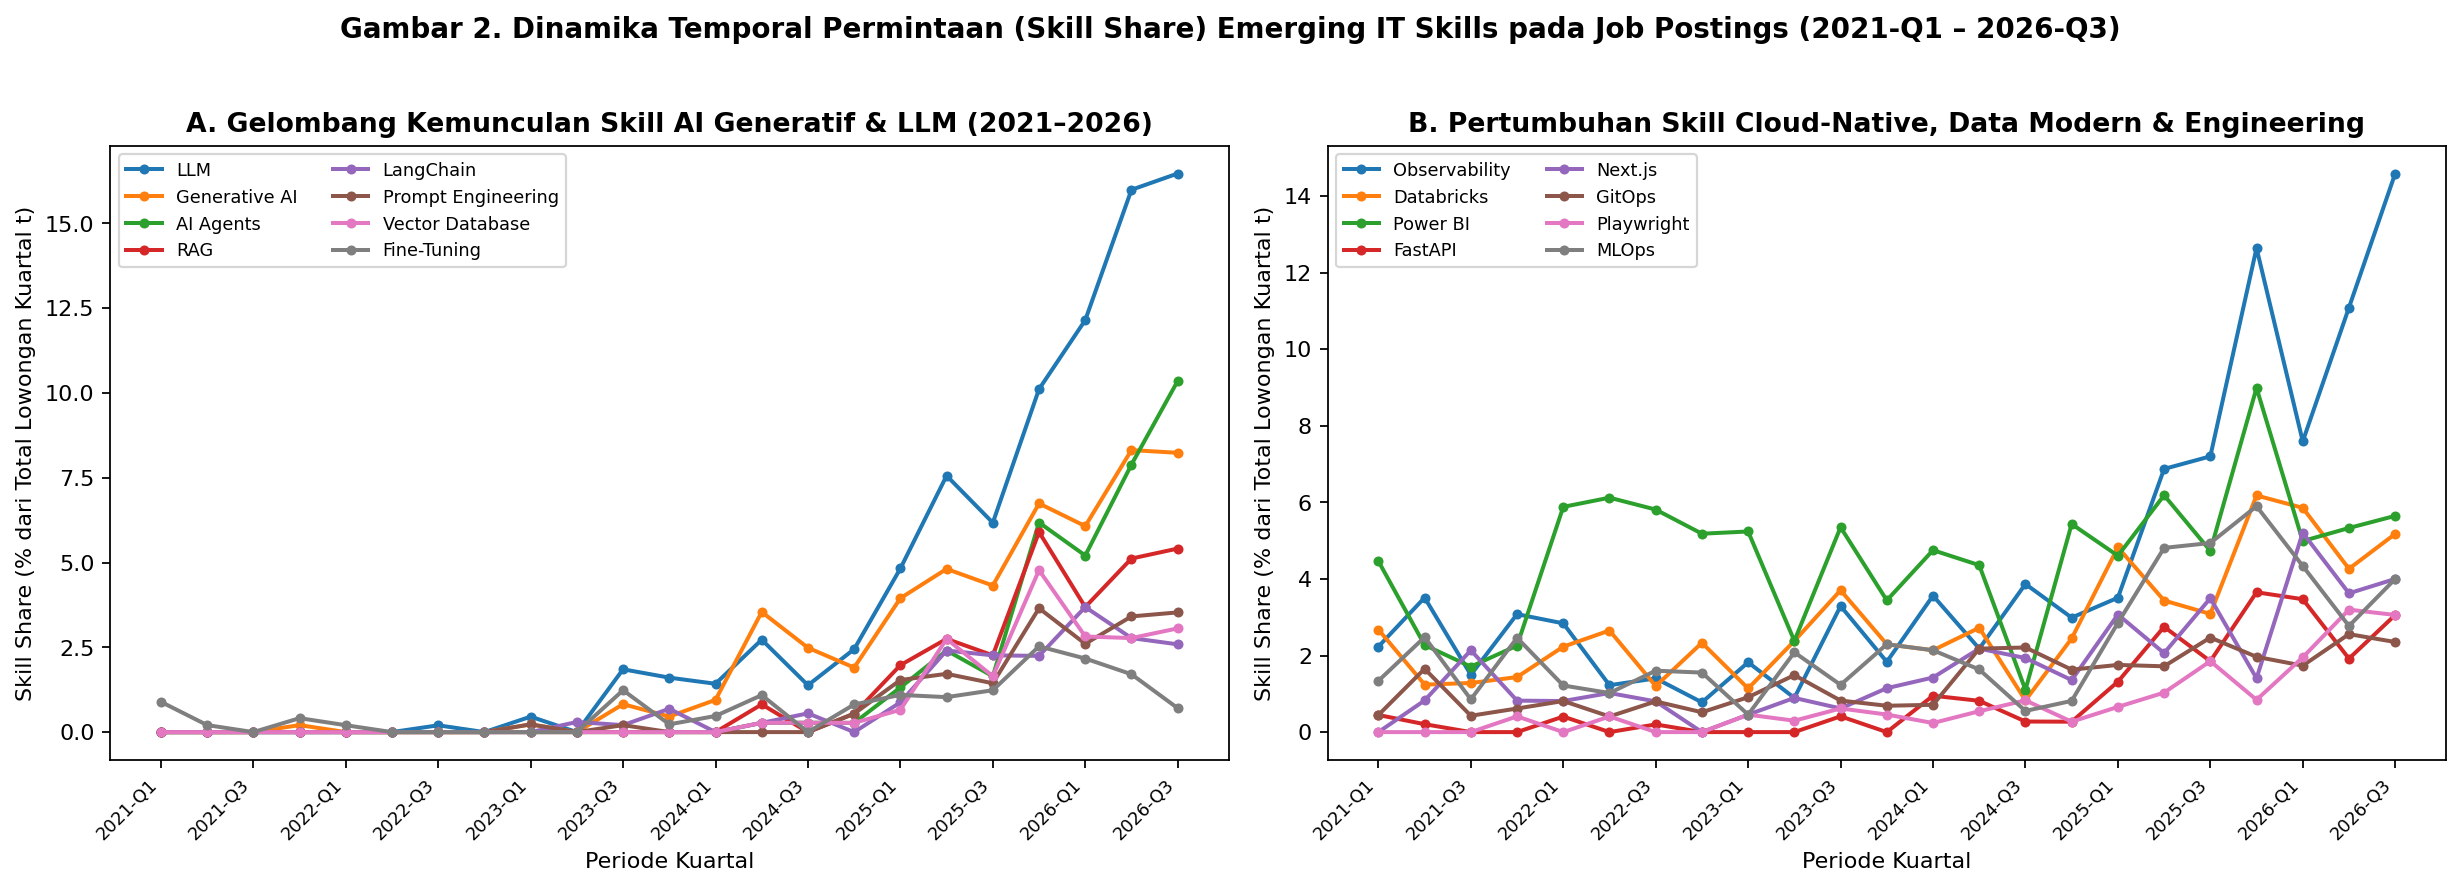

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))
q_labels = sorted(feat_df["year_quarter"].unique())
genai_skills = ["LLM", "Generative AI", "AI Agents", "RAG", "LangChain", "Prompt Engineering", "Vector Database", "Fine-Tuning"]
infra_skills = ["Observability", "Databricks", "Power BI", "FastAPI", "Next.js", "GitOps", "Playwright", "MLOps"]
for ax_idx, (title_str, sk_list) in enumerate([
    ("A. Gelombang Kemunculan Skill AI Generatif & LLM (2021–2026)", genai_skills),
    ("B. Pertumbuhan Skill Cloud-Native, Data Modern & Engineering", infra_skills),
]):
    ax = axes[ax_idx]
    for sk in sk_list:
        sub = feat_df[feat_df["skill"] == sk].sort_values("quarter_idx")
        if len(sub) > 0:
            ax.plot(sub["quarter_idx"], sub["skill_share"] * 100.0, marker="o", markersize=3.5, linewidth=1.8, label=sk)
    ax.set_xticks(np.arange(0, len(q_labels), 2))
    ax.set_xticklabels(q_labels[::2], rotation=45, ha="right", fontsize=8)
    ax.set_title(title_str, fontweight="bold")
    ax.set_ylabel("Skill Share (% dari Total Lowongan Kuartal t)")
    ax.set_xlabel("Periode Kuartal")
    ax.legend(loc="upper left", fontsize=8, ncol=2)
fig.suptitle("Gambar 2. Dinamika Temporal Permintaan (Skill Share) Emerging IT Skills pada Job Postings (2021-Q1 – 2026-Q3)", fontsize=12.5, fontweight="bold", y=1.02)
fig.tight_layout()
cfg.figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(cfg.figures_dir / "fig2_emerging_skills_trajectories.png", dpi=220, bbox_inches="tight")
plt.show()
